In [ ]:
# Install Kaggle CLI
!pip install -q kaggle

# Upload kaggle.json
from google.colab import files
print("Upload your kaggle.json:")
files.upload()

# Configure Kaggle credentials
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download and unzip dataset directly into Colab storage
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
!unzip -q chest-xray-pneumonia.zip -d ./chest_xray_data

Upload your kaggle.json:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [01:56<00:00, 21.1MB/s]



In [ ]:
import os
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing import image

In [ ]:
# Confirm Hardware Acceleration
print("GPU Status:", "Available" if tf.config.list_physical_devices('GPU') else "Not Found (Running on CPU)")

GPU Status: Available


In [ ]:
# 1. PATH CONFIGURATION & HYPERPARAMETERS
# -------------------------------------------------------------
BASE_DIR = 'chest_xray_data/chest_xray'
TRAIN_DIR = os.path.join(BASE_DIR, 'train')
VAL_DIR   = os.path.join(BASE_DIR, 'val')
TEST_DIR  = os.path.join(BASE_DIR, 'test')

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10

In [ ]:
# 2. LOAD DATASETS VIA TF.DATA
# -------------------------------------------------------------
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False
)

class_names = train_ds.class_names
print("Detected Classes:", class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Detected Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
# Optimize pipeline speed
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)



In [ ]:
# 3. BALANCED CLASS WEIGHTS CALCULATION
# -------------------------------------------------------------
train_labels = []
for _, labels in tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='binary', shuffle=False
):
    train_labels.extend(labels.numpy().flatten())

class_weights_vals = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=np.array(train_labels)
)
class_weights = dict(enumerate(class_weights_vals))
print("Computed Class Weights:", class_weights)

Found 5216 files belonging to 2 classes.
Computed Class Weights: {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}


In [ ]:
# 4. DATA AUGMENTATION LAYER
# -------------------------------------------------------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.08),
], name="data_augmentation")

In [ ]:
# 5. MODEL ARCHITECTURE 1: CUSTOM CNN
# -------------------------------------------------------------
def build_custom_cnn():
    inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1./255)(x)

    # Block 1
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 2
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 3
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Dense Classification Head
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs, outputs, name="Custom_CNN")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model



In [ ]:
# 6. MODEL ARCHITECTURE 2: DENSENET121 TRANSFER LEARNING
# -------------------------------------------------------------
def build_transfer_model():
    base_model = DenseNet121(
        weights='imagenet',
        include_top=False,
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
    )
    base_model.trainable = False  # Freeze pretrained ImageNet weights

    inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    x = data_augmentation(inputs)
    x = tf.keras.applications.densenet.preprocess_input(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs, outputs, name="DenseNet121_Transfer")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

In [ ]:
# 7. MODEL TRAINING
# -------------------------------------------------------------
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train Custom CNN
print("\n" + "="*50)
print("TRAINING MODEL 1: Custom CNN")
print("="*50)
custom_cnn = build_custom_cnn()
history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=[early_stop]
)

# Train Transfer Learning Model
print("\n" + "="*50)
print("TRAINING MODEL 2: Transfer Learning (DenseNet121)")
print("="*50)
transfer_model = build_transfer_model()
history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=[early_stop]
)




TRAINING MODEL 1: Custom CNN
Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 58s 277ms/step - accuracy: 0.8892 - auc: 0.9401 - loss: 0.3973 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 8.9754
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.9099 - auc: 0.9685 - loss: 0.2286 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 9.6241
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.9222 - auc: 0.9770 - loss: 0.1967 - val_accuracy: 0.5625 - val_auc: 0.6875 - val_loss: 3.1478
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 20s 121ms/step - accuracy: 0.9358 - auc: 0.9827 - loss: 0.1669 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.2248
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 20s 121ms/step - accuracy: 0.9377 - auc: 0.9832 - loss: 0.1644 - val_accuracy: 0.7500 - val_auc: 0.9922 - val_loss: 0.4291
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 20s 122ms/step - accuracy: 0.9398 - auc: 0.9845 - loss: 0.1571 - val_accuracy: 0.7500 - val_auc: 1.0000 - val_loss:


EVALUATION RESULTS: Custom_CNN
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step
              precision    recall  f1-score   support

      NORMAL       0.91      0.82      0.86       234
   PNEUMONIA       0.90      0.95      0.92       390

    accuracy                           0.90       624
   macro avg       0.90      0.88      0.89       624
weighted avg       0.90      0.90      0.90       624



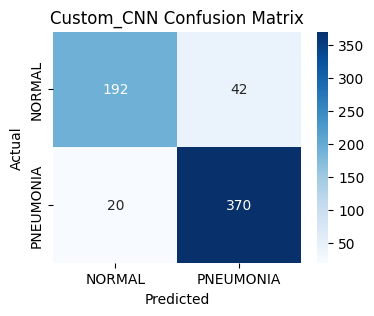


EVALUATION RESULTS: DenseNet121_Transfer
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 316ms/step
              precision    recall  f1-score   support

      NORMAL       0.89      0.83      0.86       234
   PNEUMONIA       0.90      0.94      0.92       390

    accuracy                           0.90       624
   macro avg       0.90      0.89      0.89       624
weighted avg       0.90      0.90      0.90       624



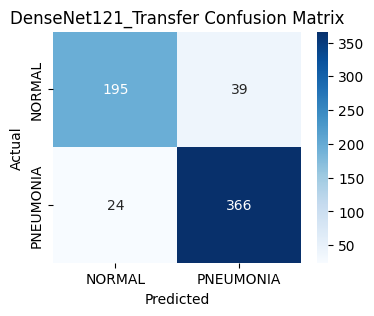

In [ ]:
# 8. TEST SET EVALUATION & CONFUSION MATRICES
# -------------------------------------------------------------
y_true = []
for _, labels in test_ds:
    y_true.extend(labels.numpy().flatten())
y_true = np.array(y_true)

for model_obj in [custom_cnn, transfer_model]:
    print("\n" + "="*50)
    print(f"EVALUATION RESULTS: {model_obj.name}")
    print("="*50)

    preds_probs = model_obj.predict(test_ds).flatten()
    preds = (preds_probs >= 0.5).astype(int)

    print(classification_report(y_true, preds, target_names=class_names))

    cm = confusion_matrix(y_true, preds)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{model_obj.name} Confusion Matrix")
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()



SAMPLE TEST PREDICTION VISUALIZATION
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


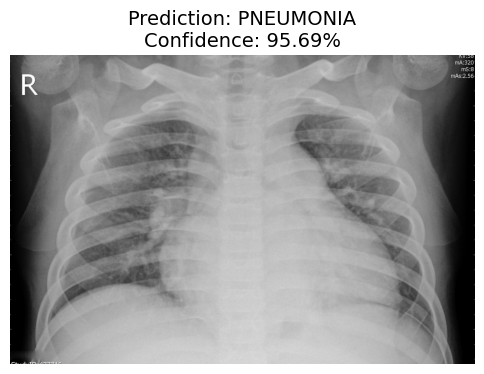

Prediction: PNEUMONIA
Confidence: 95.69%


In [ ]:
# 9. SINGLE TEST IMAGE INFERENCE WITH CONFIDENCE DISPLAY
# -------------------------------------------------------------
print("\n" + "="*50)
print("SAMPLE TEST PREDICTION VISUALIZATION")
print("="*50)

# Pick a random image from the test set
sample_images = glob.glob(f"{TEST_DIR}/*/*.*")
img_path = random.choice(sample_images)

# Prepare image for prediction
img = image.load_img(img_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_batch = np.expand_dims(img_array, axis=0)

# Predict using the trained Transfer Learning model
raw_prediction = transfer_model.predict(img_batch)[0][0]

# Compute class and confidence percentage
if raw_prediction >= 0.5:
    pred_label = "PNEUMONIA"
    confidence = raw_prediction * 100
else:
    pred_label = "NORMAL"
    confidence = (1 - raw_prediction) * 100

# Visual output matching prediction layout
plt.figure(figsize=(6, 6))
plt.imshow(image.load_img(img_path), cmap='gray')
plt.axis('off')
plt.title(f"Prediction: {pred_label}\nConfidence: {confidence:.2f}%", fontsize=14)
plt.show()

print(f"Prediction: {pred_label}")
print(f"Confidence: {confidence:.2f}%")